In [1]:
import sys

print(sys.executable)
print(sys.version)

/home/bily/python/forest_harvest/.venv/bin/python
3.12.13 (main, Jun 11 2026, 04:03:26) [Clang 22.1.3 ]


In [2]:
from pystac_client import Client
import odc.stac, odc.geo.xr
import geopandas as gpd
import rasterio.features
import matplotlib.pyplot as plt
from shapely.geometry import shape


In [3]:
# Let's Load AOI and get a comparison over time to find harvests and burns
aoi = gpd.read_file(r"/home/bily/python/forest_harvest/data/stMary_aoi.shp")
# convert the aoi to WGS84
aoi_wgs = aoi.to_crs("EPSG:4326")
bbox = aoi_wgs.total_bounds
print(bbox)

[-114.43805411   46.2757663  -114.01293748   46.62299715]


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

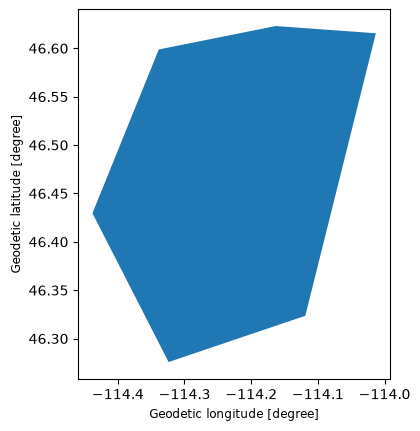

In [4]:
# This is a hand drawn aoi around St. Mary in the Bitterroot Mountains
# A burn happened here recently and we will try to detect it
aoi_wgs.plot()

In [5]:
# Search the same season in two years (the fire was in the early fall of 2024)

cat = Client.open("https://earth-search.aws.element84.com/v1")

def search(dates):
    return cat.search(collections=["sentinel-2-c1-l2a"],
                      bbox=bbox,
                      datetime=dates,
                      query={"eo:cloud_cover": {"lt": 40}}).item_collection()

# Capture most of the growing season, and try to end before smoke season
before_items = search("2024-05-15/2024-07-31")
after_items = search("2025-05-15/2025-07-31")

len(before_items), len(after_items)

/home/bily/python/forest_harvest/.venv/lib/python3.12/site-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


(37, 45)

In [6]:
# Load the bands that I am interested in
def load(items):
    return odc.stac.load(items,
                         bands=["nir", "swir22", "scl"], bbox=bbox,
                         resolution=10,
                         groupby="solar_day",
                         chunks={})

before, after = load(before_items), load(after_items)

In [7]:
# Mask clouds and get median NBR per period
BAD_FILTER = [0, 1, 2, 3, 8, 9, 10] # no-data, saturated, shadow, cloud, cirrus

def nbr_median(ds):
    clear = ~ds.scl.isin(BAD_FILTER)
    nir = ds.nir.where(clear).astype("float32")
    swir = ds.swir22.where(clear).astype("float32")
    return ((nir-swir)/(nir+swir)).median("time").compute()

nbr_before, nbr_after = nbr_median(before), nbr_median(after)
dnbr = nbr_before - nbr_after # positive = vegetation lost

/home/bily/python/forest_harvest/.venv/lib/python3.12/site-packages/rasterio/warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


In [ ]:
# Take a look at the images
fig, ax = plt.subplots(1, 3, figsize=(16,5))
nbr_before.plot(ax=ax[0], vmin=-0.2, vmax=0.8, cmap="RdYlGn"); ax[0].set_title("NBR 2024")
nbr_after.plot(ax=ax[1], vmin=-0.2, vmax=0.8, cmap="RdYlGn"); ax[1].set_title("NBR 2025")
dnbr.plot(ax=ax[2], vmin=-0.5, vmax=0.5, cmap="RdBu_r"); ax[2].set_title("dNBR")


In [ ]:
# explore the dNBR
dnbr.plot.hist(bins=100, range=(-0.5, 0.8))